
## 1. Business Objective

The objective of this analysis is to evaluate transaction patterns using the validated Gold tables produced by the Databricks pipeline.

The analysis focuses on discounts, voids, missing-payment signals, unusual transaction patterns, and differences across locations, business dates, and employee profiles.

The results are intended to support operational monitoring and prioritize transactions for further investigation.

## 2. Analytical Approach

The notebook uses the Medallion architecture outputs:

- **Bronze:** Raw source data with ingestion traceability.
- **Silver:** Cleaned and standardized transaction records and transaction details.
- **Gold:** Aggregated business metrics and transaction-level risk indicators.

## 3. Business Questions

1. What proportion of transactions has at least one risk indicator?
2. How do discount and void amounts compare with gross sales?
3. How do transaction metrics vary across business dates and locations?
4. Which location and revenue-center combinations have unusual metrics relative to comparable groups?
5. What patterns appear in the employee-level metrics?

## 4. Important Limitation

Risk indicators are not proof of fraud or misconduct. They identify records or patterns that may deserve additional review. Conclusions must be based on the executed results and the data-quality evidence.

In [0]:
from pyspark.sql import functions as F

# Todas las tablas del proyecto están en este esquema.
SCHEMA = "workspace.default"

TABLES = {
    "transactions": f"{SCHEMA}.p2_team_gold_transaction_risk_flags",
    "daily": f"{SCHEMA}.p2_team_gold_daily_risk_metrics",
    "locations": f"{SCHEMA}.p2_team_gold_location_risk_comparison",
    "employees": f"{SCHEMA}.p2_team_gold_employee_risk_profile"
}

# Verificar que existan las cuatro tablas antes de analizar.
missing_tables = []

for label, table_name in TABLES.items():
    try:
        spark.table(table_name).limit(1).collect()
        print(f"OK | {label} | {table_name}")
    except Exception as e:
        missing_tables.append(table_name)
        print(f"ERROR | No se pudo acceder a {table_name}")
        print(str(e).splitlines()[0])

if missing_tables:
    raise RuntimeError(
        "Faltan tablas Gold. Ejecuta primero el notebook 07 "
        "con stage='all' o completa las etapas pendientes. "
        "Tablas faltantes: " + ", ".join(missing_tables)
    )

# Cargar las tablas para el análisis.
tx = spark.table(TABLES["transactions"])
daily = spark.table(TABLES["daily"])
locations = spark.table(TABLES["locations"])
employees = spark.table(TABLES["employees"])

print("Preflight completado: las cuatro tablas Gold están disponibles.")

OK | transactions | workspace.default.p2_team_gold_transaction_risk_flags
OK | daily | workspace.default.p2_team_gold_daily_risk_metrics
OK | locations | workspace.default.p2_team_gold_location_risk_comparison
OK | employees | workspace.default.p2_team_gold_employee_risk_profile
Preflight completado: las cuatro tablas Gold están disponibles.


## 5. Executive KPIs

This section calculates the main indicators used to summarize transaction activity and potential operational risk.

- **Checks evaluated:** number of transaction records in the Gold transaction table.
- **Checks with risk signals:** records with a risk score greater than zero.
- **Risk-signal rate:** percentage of evaluated checks with at least one signal.
- **Discount-to-gross-sales ratio:** total discounts divided by gross sales.
- **Void-to-gross-sales ratio:** total void amount divided by gross sales.

These measures describe the processed data and should be interpreted in the context of the source definitions and data-quality results.

In [0]:
# Resumen de los indicadores a nivel de transacción.
totals = tx.agg(
    F.count("*").alias("checks_evaluated"),

    F.sum(
        F.when(F.col("risk_score") > 0, 1).otherwise(0)
    ).alias("checks_with_signals"),

    F.sum(
        F.coalesce(F.col("total_gross_price"), F.lit(0.0))
    ).alias("gross_sales"),

    F.sum(
        F.coalesce(F.col("discount_total_amount"), F.lit(0.0))
    ).alias("discount_amount"),

    F.sum(
        F.coalesce(F.col("void_amount"), F.lit(0.0))
    ).alias("void_amount")
).first()

# Convertir a valores numéricos.
checks_evaluated = int(totals["checks_evaluated"] or 0)
checks_with_signals = int(totals["checks_with_signals"] or 0)
gross_sales = float(totals["gross_sales"] or 0)
discount_amount = float(totals["discount_amount"] or 0)
void_amount = float(totals["void_amount"] or 0)

# Evitar divisiones entre cero.
def safe_percentage(numerator, denominator):
    if denominator is None or denominator == 0:
        return None
    return 100.0 * float(numerator or 0) / float(denominator)

risk_signal_rate = safe_percentage(
    checks_with_signals, checks_evaluated
)

discount_to_sales = safe_percentage(
    discount_amount, gross_sales
)

void_to_sales = safe_percentage(
    void_amount, gross_sales
)

# Mostrar los resultados.
kpi_data = [
    ("Checks evaluated", checks_evaluated, "checks"),
    ("Checks with risk signals", checks_with_signals, "checks"),
    ("Risk-signal rate", risk_signal_rate, "%"),
    ("Gross sales", gross_sales, "source currency"),
    ("Discount amount", discount_amount, "source currency"),
    ("Discount-to-gross-sales ratio", discount_to_sales, "%"),
    ("Void amount", void_amount, "source currency"),
    ("Void-to-gross-sales ratio", void_to_sales, "%")
]

from pyspark.sql.types import StructType, StructField, StringType, DoubleType

kpi_df = spark.createDataFrame(
    kpi_data,
    StructType([
        StructField("KPI", StringType(), True),
        StructField("Value", DoubleType(), True),
        StructField("Unit", StringType(), True)
    ])
)

display(kpi_df)

KPI,Value,Unit
Checks evaluated,2142846.0,checks
Checks with risk signals,109083.0,checks
Risk-signal rate,5.090566470945649,%
Gross sales,8.731774367954108E7,source currency
Discount amount,3023167.750004598,source currency
Discount-to-gross-sales ratio,3.4622605012558734,%
Void amount,726216.499999765,source currency
Void-to-gross-sales ratio,0.8316940743052212,%


## 6. Daily and Location Trends

This section examines how discount and void ratios change across business dates and locations.

The daily Gold table contains one record per location and business date. Comparing these metrics helps identify patterns that may require operational review.

The analysis considers both the absolute transaction volume and the ratios relative to gross sales. High values should be investigated in context rather than interpreted as proof of wrongdoing.

In [0]:
# Comprobar que las columnas necesarias existen.
required_daily_columns = [
    "business_date",
    "LocationId",
    "location_name",
    "checks",
    "gross_sales",
    "discount_pct",
    "void_pct",
    "rate_fully_voided",
    "rate_high_discount",
    "rate_no_payment",
    "rate_discount_both_levels",
    "rate_checks_with_void"
]

missing_columns = [
    c for c in required_daily_columns
    if c not in daily.columns
]

if missing_columns:
    raise ValueError(
        f"Faltan columnas en la tabla diaria: {missing_columns}"
    )

daily_view = daily.select(*required_daily_columns)

print("Daily metrics — most recent business dates")
display(
    daily_view
    .orderBy(
        F.col("business_date").desc(),
        F.col("LocationId")
    )
    .limit(100)
)

print("Locations with the highest discount-to-sales ratios")
display(
    daily_view
    .filter(F.col("gross_sales") > 0)
    .orderBy(F.col("discount_pct").desc())
    .limit(20)
)

print("Locations with the highest void-to-sales ratios")
display(
    daily_view
    .filter(F.col("gross_sales") > 0)
    .orderBy(F.col("void_pct").desc())
    .limit(20)
)

Daily metrics — most recent business dates


business_date,LocationId,location_name,checks,gross_sales,discount_pct,void_pct,rate_fully_voided,rate_high_discount,rate_no_payment,rate_discount_both_levels,rate_checks_with_void
2026-08-20,1,Topeka,202,7394.049999999986,0.0334187623832677,0.005035129597446606,0.009900990099009901,0.04950495049504951,0.01485148514851485,0.0,0.024752475247524754
2026-08-20,2,Manhattan,103,3847.569999999996,0.07435082402659349,0.02050644952528481,0.0,0.10679611650485436,0.009708737864077669,0.009708737864077669,0.05825242718446602
2026-08-20,3,Old Cheney,80,2317.6800000000003,0.051944185564875206,0.02596993545269407,0.025,0.075,0.0,0.0125,0.0625
2026-08-20,5,North Platte,210,8136.249999999989,0.02869257950530039,0.014467352895990186,0.009523809523809525,0.03333333333333333,0.0,0.0,0.04285714285714286
2026-08-20,6,Scottsbluff,136,5435.8599999999915,0.02477436872914317,0.005886832994227233,0.007352941176470588,0.03676470588235294,0.0,0.0,0.014705882352941176
2026-08-20,8,Gateway,127,4880.939999999993,0.024898892426458867,0.0027125922465754586,0.0,0.05511811023622047,0.0,0.0,0.015748031496062992
2026-08-20,9,Emporia,180,7265.90999999999,0.016088831268210063,0.01111354255695434,0.0,0.022222222222222223,0.0,0.0,0.022222222222222223
2026-08-20,11,Lubbock S Loop,89,3264.8900000000003,0.017617745161399002,0.0048975616330106065,0.011235955056179775,0.02247191011235955,0.0,0.0,0.02247191011235955
2026-08-20,12,Amarillo Soncy,96,3426.209999999999,0.02173246823749858,0.008691819824237279,0.020833333333333332,0.03125,0.0,0.0,0.03125
2026-08-20,13,Wichita Falls,60,2129.0800000000004,0.020797715445168802,0.005481240723692862,0.0,0.03333333333333333,0.0,0.0,0.05


Locations with the highest discount-to-sales ratios


business_date,LocationId,location_name,checks,gross_sales,discount_pct,void_pct,rate_fully_voided,rate_high_discount,rate_no_payment,rate_discount_both_levels,rate_checks_with_void
2026-06-10,54,Crestwood,17,881.7099999999999,0.8797450408864593,0.0,0.0,0.8235294117647058,0.0,0.0,0.0
2026-08-11,109,Mt Sterling,63,2095.6300000000006,0.2044253995218621,0.06962584043939052,0.015873015873015872,0.23809523809523808,0.0,0.015873015873015872,0.14285714285714285
2026-07-05,153,Boardman,29,1289.19,0.19879924603821006,0.04727774804334504,0.034482758620689655,0.1724137931034483,0.0,0.0,0.06896551724137931
2026-07-13,54,Crestwood,118,4645.449999999997,0.18333207762434228,0.007583764759065326,0.00847457627118644,0.211864406779661,0.0,0.00847457627118644,0.025423728813559324
2026-07-13,144,Sierra Vista,97,3686.8299999999977,0.16934059883422894,0.015370928412755685,0.030927835051546393,0.14432989690721648,0.0,0.010309278350515464,0.05154639175257732
2026-07-08,63,Peru,84,3395.43,0.15894599505806337,0.027139419749486814,0.023809523809523808,0.16666666666666666,0.011904761904761904,0.011904761904761904,0.07142857142857142
2026-05-25,182,Troy,57,2346.01,0.14564729050600805,0.01703743803308596,0.017543859649122806,0.08771929824561403,0.0,0.017543859649122806,0.07017543859649122
2026-05-04,84,Ireland Road,101,3147.2799999999993,0.144597874990468,0.011270049058234416,0.019801980198019802,0.09900990099009901,0.0,0.009900990099009901,0.0594059405940594
2026-05-19,196,Richmond IN,84,2713.7199999999993,0.14159530091534872,0.037196173518270134,0.0,0.14285714285714285,0.0,0.011904761904761904,0.08333333333333333
2026-05-24,54,Crestwood,102,4610.969999999996,0.13678249912708185,0.05521614757849222,0.0196078431372549,0.1568627450980392,0.00980392156862745,0.029411764705882353,0.049019607843137254


Locations with the highest void-to-sales ratios


business_date,LocationId,location_name,checks,gross_sales,discount_pct,void_pct,rate_fully_voided,rate_high_discount,rate_no_payment,rate_discount_both_levels,rate_checks_with_void
2026-06-23,69,Clinton,81,3046.529999999999,0.02243536088599161,0.141787541891923,0.024691358024691357,0.024691358024691357,0.0,0.0,0.06172839506172839
2026-06-16,122,44th & Thomas,158,7294.319999999992,0.010672687789951644,0.1178506015639568,0.0,0.012658227848101266,0.0,0.0,0.0189873417721519
2026-07-27,148,Desert Sky,111,4050.2699999999963,0.009009275924814897,0.0961960560653982,0.02702702702702703,0.02702702702702703,0.0,0.0,0.036036036036036036
2026-07-26,19,Grand Island,83,3311.9299999999985,0.059678193681629764,0.09556965274024518,0.04819277108433735,0.060240963855421686,0.0,0.0,0.12048192771084337
2026-05-18,19,Grand Island,75,2628.7299999999996,0.017301130203558373,0.08702681523016818,0.06666666666666667,0.05333333333333334,0.0,0.0,0.09333333333333334
2026-07-06,108,Nicholasville,67,1987.2600000000007,0.04211326147559955,0.08623934462526289,0.014925373134328358,0.1044776119402985,0.0,0.0,0.05970149253731343
2026-08-15,15,Ardmore,102,3700.589999999998,0.032070561721239066,0.08619436360147982,0.0196078431372549,0.0784313725490196,0.0,0.0,0.08823529411764706
2026-04-28,108,Nicholasville,59,1743.0200000000002,0.055719383598581765,0.0832979541255981,0.0,0.06779661016949153,0.0,0.0,0.05084745762711865
2026-05-31,80,Munster,165,6416.519999999994,0.0625245460155973,0.08138211990300047,0.024242424242424242,0.10303030303030303,0.0,0.012121212121212121,0.15151515151515152
2026-06-04,1,Topeka,210,7471.41999999999,0.033396596630894844,0.08126032266958635,0.014285714285714285,0.047619047619047616,0.06190476190476191,0.0,0.06666666666666667


## 7. Location and Revenue-Center Comparison

This section compares locations and revenue centers using discount and void ratios.

The Gold table includes peer-comparison indicators calculated by the pipeline. These indicators help identify combinations with unusually high or low metrics relative to comparable groups, subject to the configured minimum transaction count and the availability of valid comparison statistics.

An outlier is a signal for investigation, not a conclusion about fraud or employee conduct.

In [0]:
required_location_columns = [
    "LocationId",
    "location_name",
    "RevenueCenterId",
    "revenue_center_name",
    "checks",
    "gross_sales",
    "void_amount",
    "discount_amount",
    "void_pct",
    "discount_pct",
    "void_z",
    "discount_z",
    "is_outlier"
]

missing_columns = [
    c for c in required_location_columns
    if c not in locations.columns
]

if missing_columns:
    raise ValueError(
        f"Faltan columnas en la tabla de ubicaciones: {missing_columns}"
    )

location_view = locations.select(*required_location_columns)

print("Highest void-to-sales ratios by location and revenue center")
display(
    location_view
    .filter(
        (F.col("checks") > 0) &
        (F.col("gross_sales") > 0)
    )
    .orderBy(F.col("void_pct").desc())
    .limit(20)
)

print("Highest discount-to-sales ratios by location and revenue center")
display(
    location_view
    .filter(
        (F.col("checks") > 0) &
        (F.col("gross_sales") > 0)
    )
    .orderBy(F.col("discount_pct").desc())
    .limit(20)
)

print("Location/revenue-center combinations flagged as outliers")
display(
    location_view
    .filter(F.col("is_outlier") == True)
    .orderBy(
        F.abs(F.col("void_z")).desc_nulls_last()
    )
)

Highest void-to-sales ratios by location and revenue center


LocationId,location_name,RevenueCenterId,revenue_center_name,checks,gross_sales,void_amount,discount_amount,void_pct,discount_pct,void_z,discount_z,is_outlier
131,Foothills Mall,6,Delivery Service,3,6.48,6.0,0.0,0.9259259259259258,0.0,null,null,null
69,Clinton,7,Catering,3,476.0,384.0,0.0,0.8067226890756303,0.0,null,null,null
76,Lima Road,6,Delivery Service,3,33.77,14.49,0.0,0.42907906425821735,0.0,null,null,null
183,Union Centre,6,Delivery Service,4,105.96,25.0,41.98,0.23593808984522463,0.39618724046810117,null,null,null
126,83rd & Bell,7,Catering,10,212.32,35.48,30.619999999999997,0.1671062547098719,0.14421627731725697,null,null,null
178,Brownsville TX,3,Online AS,9,207.58000000000004,28.0,35.84,0.1348877541188939,0.1726563252721842,null,null,null
33,Ocean Springs,6,Delivery Service,10,142.89000000000001,14.99,25.02,0.1049058716495206,0.17509972706277555,null,null,null
93,Lima,6,Delivery Service,9,181.08,16.47,52.46,0.09095427435387672,0.289706207201237,null,null,null
48,Portland,2,To Go,314,8024.319999999971,568.51,874.9500000000003,0.07084837095230526,0.1090372766788966,5.230448237970407,-0.2178597238895948,true
84,Ireland Road,6,Delivery Service,7,73.21999999999998,4.99,59.480000000000004,0.06815077847582629,0.8123463534553403,null,null,null


Highest discount-to-sales ratios by location and revenue center


LocationId,location_name,RevenueCenterId,revenue_center_name,checks,gross_sales,void_amount,discount_amount,void_pct,discount_pct,void_z,discount_z,is_outlier
115,Highland Heights,6,Delivery Service,1,16.99,0.0,16.99,0.0,1.0,null,null,null
115,Highland Heights,7,Catering,2,27.48,0.0,27.48,0.0,1.0,null,null,null
122,44th & Thomas,6,Delivery Service,1,15.49,0.0,15.49,0.0,1.0,null,null,null
39,Corpus Christi,6,Delivery Service,1,20.99,0.0,20.99,0.0,1.0,null,null,null
182,Troy,6,Delivery Service,2,51.97,0.0,51.97,0.0,1.0,null,null,null
91,Findlay,6,Delivery Service,6,44.16,0.0,44.16,0.0,1.0,null,null,null
13,Wichita Falls,6,Delivery Service,1,14.98,0.0,14.98,0.0,1.0,null,null,null
27,Durant,7,Catering,1,16.49,0.0,16.49,0.0,1.0,null,null,null
72,Fort Wayne,6,Delivery Service,1,30.98,0.0,30.98,0.0,1.0,null,null,null
167,Hilliard Rome,7,Catering,1,17.49,0.0,17.49,0.0,1.0,null,null,null


Location/revenue-center combinations flagged as outliers


LocationId,location_name,RevenueCenterId,revenue_center_name,checks,gross_sales,void_amount,discount_amount,void_pct,discount_pct,void_z,discount_z,is_outlier
87,Warsaw,11,Door Dash,2556,96736.60999999946,66.74,0.0,6.899146042020737E-4,0.0,10.15440249544787,null,true
87,Warsaw,12,Uber Eats,219,9682.849999999995,5.98,0.0,6.175867642274748E-4,0.0,9.674882332569364,null,true
1,Topeka,4,Online,425,15541.989999999936,465.52000000000004,155.29,0.02995240635208245,0.009991641996938657,8.798876079222893,-0.8960074542578643,true
48,Portland,2,To Go,314,8024.319999999971,568.51,874.9500000000003,0.07084837095230526,0.1090372766788966,5.230448237970407,-0.2178597238895948,true
80,Munster,1,In-Store,10960,483109.76999997086,13989.959999999906,24664.329999999776,0.028958139265121363,0.05105326269845725,4.832264676249445,1.0557515712861247,true
1,Topeka,11,Door Dash,2487,94641.19999999992,29.98,0.0,3.167753578779646E-4,0.0,4.5985766081466215,null,true
187,Woodman & Park,2,To Go,1167,30170.130000000205,1771.5800000000006,7100.029999999972,0.0587196674326557,0.2353330926979739,4.060606547185747,2.18485034716904,true
24,Columbus,4,Online,828,36262.21000000006,491.15000000000003,219.54,0.013544403388541383,0.006054236628159167,3.7702721391764,-1.185100974592105,true
19,Grand Island,4,Online,785,33206.539999999986,369.63,491.90999999999997,0.01113124101457123,0.014813648154851429,3.0307039023420863,-0.5419644729794336,true
69,Clinton,1,In-Store,10406,404123.20999997563,8752.84999999995,17340.349999999897,0.021658864879353198,0.04290857236336647,2.9458221855380917,0.36169348248836763,true


## 8. Employee-Level Metrics

This section examines aggregated void and discount metrics by employee and location.

To improve comparability, the analysis filters out the placeholder employee identifier and focuses on profiles with at least 100 sold item lines, consistent with the threshold used by the pipeline's peer-comparison logic.

The metrics can help prioritize operational review, but differences may reflect legitimate differences in roles, transaction volume, or operating conditions. They must not be treated as evidence of misconduct.

In [0]:
required_employee_columns = [
    "EmployeeId",
    "LocationId",
    "checks_touched",
    "items_sold_lines",
    "gross_sales",
    "void_count",
    "void_amount",
    "void_rate_per_item",
    "void_pct_of_sales",
    "voids_no_manager_pct",
    "check_discount_count",
    "item_discount_count",
    "discount_amount_total",
    "discount_pct_of_sales",
    "void_z",
    "discount_z",
    "is_outlier"
]

missing_columns = [
    c for c in required_employee_columns
    if c not in employees.columns
]

if missing_columns:
    raise ValueError(
        f"Faltan columnas en la tabla de empleados: {missing_columns}"
    )

# Aplicar los filtros acordes con el análisis de pares del notebook 07.
employee_view = (
    employees
    .filter(
        (F.col("EmployeeId") != 0) &
        (F.col("items_sold_lines") >= 100)
    )
    .select(*required_employee_columns)
)

print("Employee profiles flagged as outliers")
display(
    employee_view
    .filter(F.col("is_outlier") == True)
    .select(
        "LocationId",
        "checks_touched",
        "items_sold_lines",
        "void_count",
        "void_pct_of_sales",
        "discount_pct_of_sales",
        "void_z",
        "discount_z",
        "is_outlier"
    )
    .orderBy(F.col("void_z").desc_nulls_last())
)

print("Highest void-to-sales ratios among eligible profiles")
display(
    employee_view
    .filter(F.col("gross_sales") > 0)
    .select(
        "LocationId",
        "checks_touched",
        "items_sold_lines",
        "void_pct_of_sales",
        "discount_pct_of_sales",
        "voids_no_manager_pct"
    )
    .orderBy(F.col("void_pct_of_sales").desc())
    .limit(20)
)

Employee profiles flagged as outliers


LocationId,checks_touched,items_sold_lines,void_count,void_pct_of_sales,discount_pct_of_sales,void_z,discount_z,is_outlier
87,44,315,31,0.38179612751099623,1.000000000000001,5.123776378659743,3.009898307096314,true
42,31,509,21,0.023615377079599615,0.0013254115979277478,4.849299226036207,-1.481731038821919,true
93,71,908,81,0.1105923539056615,0.0739856801909308,4.837737295134213,2.5312748496081072,true
11,27,416,55,0.07977659148765888,0.06979813201876496,4.742076793099143,2.5674330860741827,true
1,51,454,182,0.12008835500843842,0.007669016181872334,4.633547102791379,-0.5590092944415144,true
65,40,442,53,0.07476044163462725,0.02034972572108811,4.570010201531897,-1.1749310023168684,true
9,65,656,25,0.04068871124213186,0.02856218931662819,4.430856914566074,1.3713936522930283,true
112,12,149,7,0.07242240456653584,0.01514002854084909,4.398235997168559,-1.1480152352715203,true
170,645,7461,304,0.03013929190598602,0.027962999581526468,4.336231151383055,0.2323711856580109,true
115,24,353,12,0.06071619032570266,0.04391751762823678,4.331620403344744,0.7188111235831643,true


Highest void-to-sales ratios among eligible profiles


LocationId,checks_touched,items_sold_lines,void_pct_of_sales,discount_pct_of_sales,voids_no_manager_pct
87,44,315,0.38179612751099623,1.000000000000001,0.0
1,23,136,0.27727036305003644,0.2954748777696869,0.0
187,70,755,0.27406140834712267,0.2238168781025924,0.0
113,20,189,0.24820961246141066,0.09429113190102331,0.0
33,15,214,0.20288118981315822,0.0,0.0
69,51,528,0.1930976686047613,0.15801784057120133,0.0
108,62,679,0.15425718119761178,0.06249635348801028,0.0
1,51,454,0.12008835500843842,0.007669016181872334,0.0
93,71,908,0.1105923539056615,0.0739856801909308,0.0
69,20,231,0.10901631847816144,0.024797815492755323,0.0


## 9. Transaction Risk-Signal Analysis

The transaction-level Gold table contains four indicators:

- `risk_fully_voided`: a check has no item lines and has at least one void.
- `risk_high_discount`: the total discount is at least 50% of gross check sales, according to the current pipeline configuration.
- `risk_no_payment`: the check has item lines but no payment records.
- `risk_discount_both_levels`: discounts exist at both check and item levels.

The `risk_score` counts how many of these indicators apply to a check. It is a simple rule-based score, not a validated predictive model or a probability of fraud.

In [0]:
risk_flags = [
    "risk_fully_voided",
    "risk_high_discount",
    "risk_no_payment",
    "risk_discount_both_levels"
]

required_tx_columns = [
    "check_key",
    "risk_score",
    "total_gross_price",
    "discount_total_amount",
    "void_amount"
] + risk_flags

missing_columns = [
    c for c in required_tx_columns
    if c not in tx.columns
]

if missing_columns:
    raise ValueError(
        f"Faltan columnas en la tabla de transacciones: {missing_columns}"
    )

# Distribución del número de señales por check.
print("Risk score distribution")

score_distribution = (
    tx.groupBy("risk_score")
    .agg(F.count("*").alias("checks"))
    .orderBy("risk_score")
)

display(score_distribution)

# Contar los checks afectados por cada señal.
signal_expressions = [
    F.sum(
        F.when(F.col(flag) == True, 1).otherwise(0)
    ).alias(flag)
    for flag in risk_flags
]

signal_counts = tx.agg(
    F.count("*").alias("checks_evaluated"),
    *signal_expressions
).first()

total_checks = int(signal_counts["checks_evaluated"] or 0)

signal_rows = []

for flag in risk_flags:
    count = int(signal_counts[flag] or 0)

    percentage = (
        100.0 * count / total_checks
        if total_checks > 0
        else None
    )

    signal_rows.append(
        (flag, count, total_checks, percentage)
    )

signal_summary = spark.createDataFrame(
    signal_rows,
    [
        "risk_signal",
        "checks_with_signal",
        "checks_evaluated",
        "percentage_of_checks"
    ]
)

display(signal_summary)

Risk score distribution


risk_score,checks
0,2033763
1,104323
2,4754
3,6


risk_signal,checks_with_signal,checks_evaluated,percentage_of_checks
risk_fully_voided,8688,2142846,0.40544210829896316
risk_high_discount,94839,2142846,4.425843014383675
risk_no_payment,2693,2142846,0.12567398683806488
risk_discount_both_levels,7629,2142846,0.35602185131362685


#Visualizations and analysis of Gold tables.

Setup OK


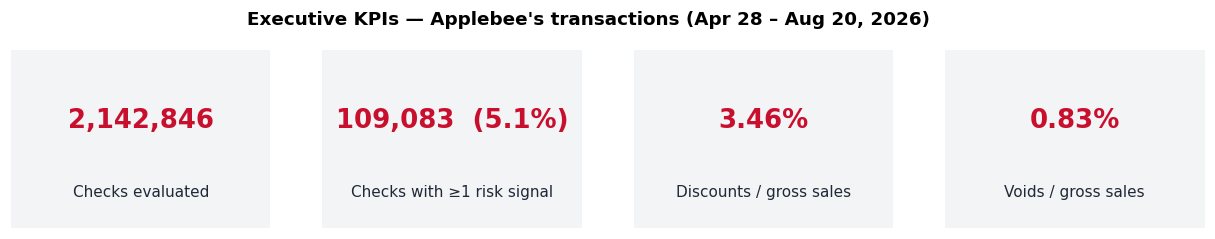

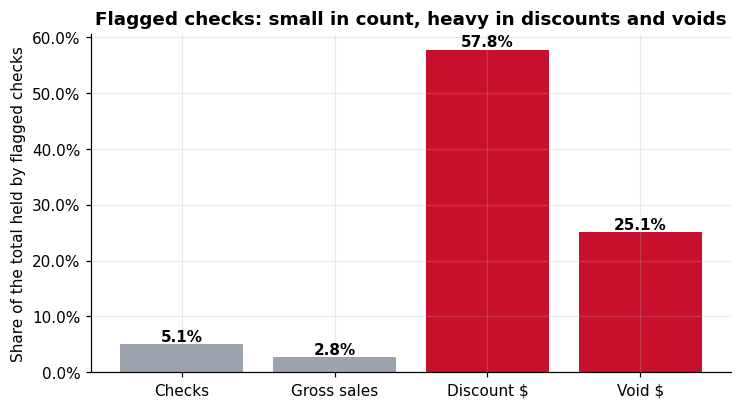

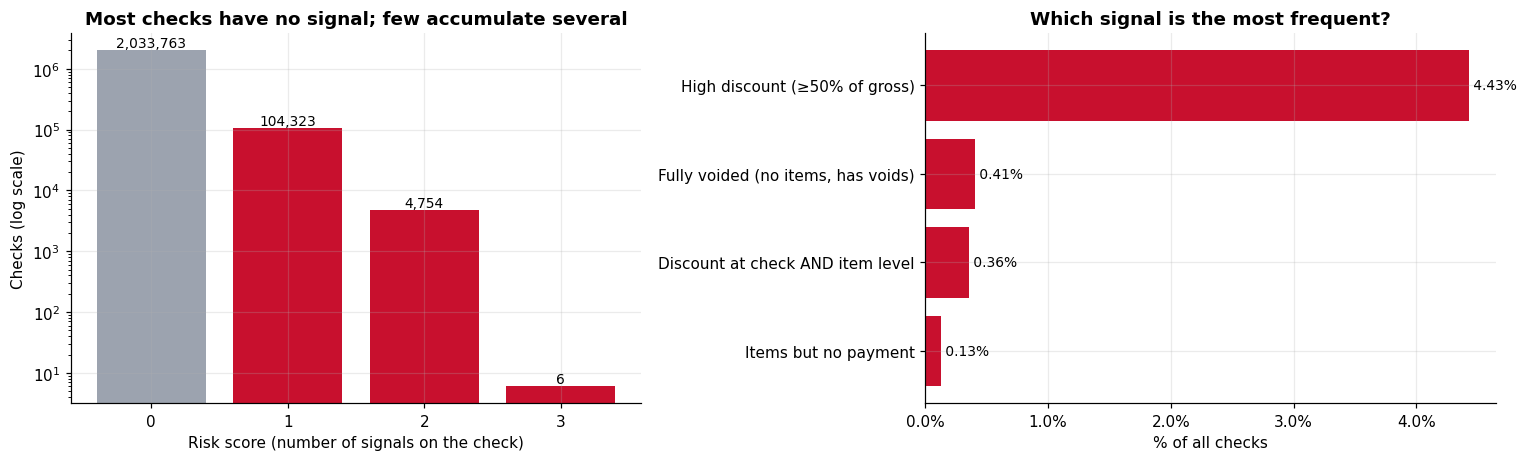

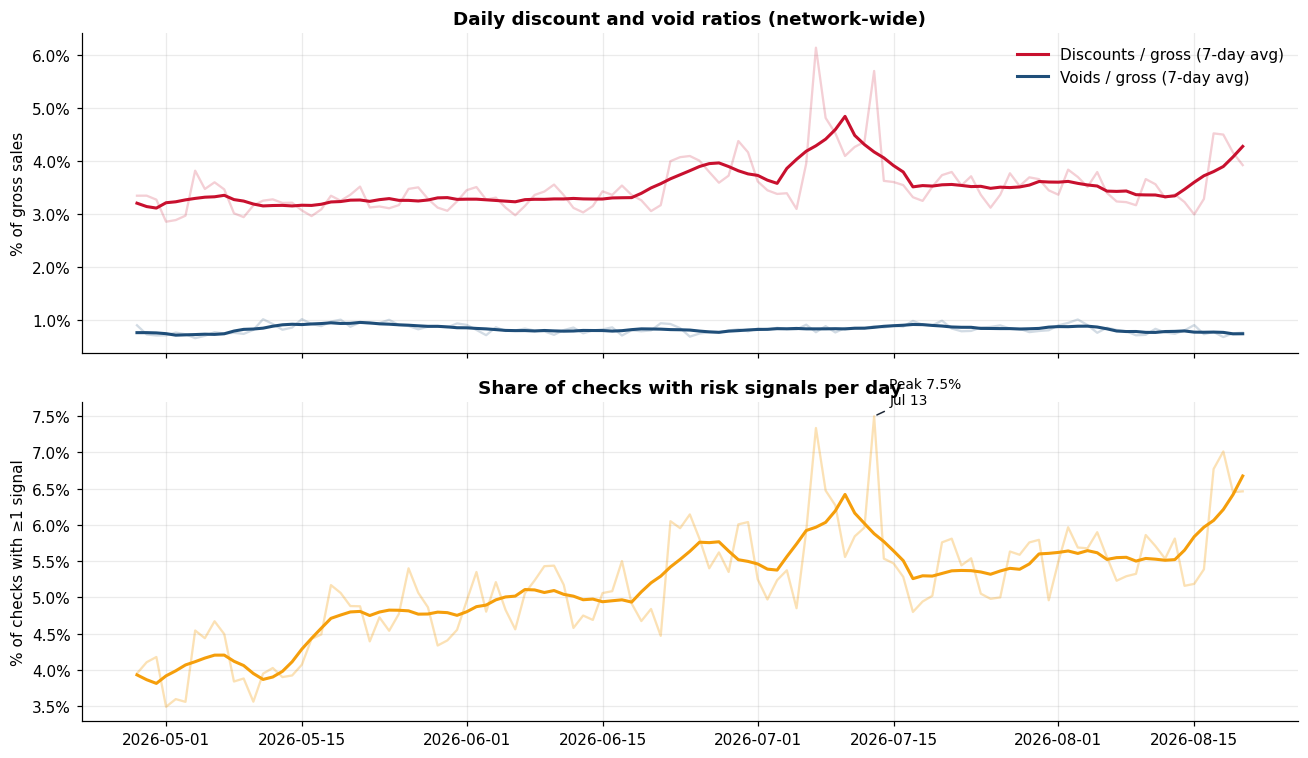

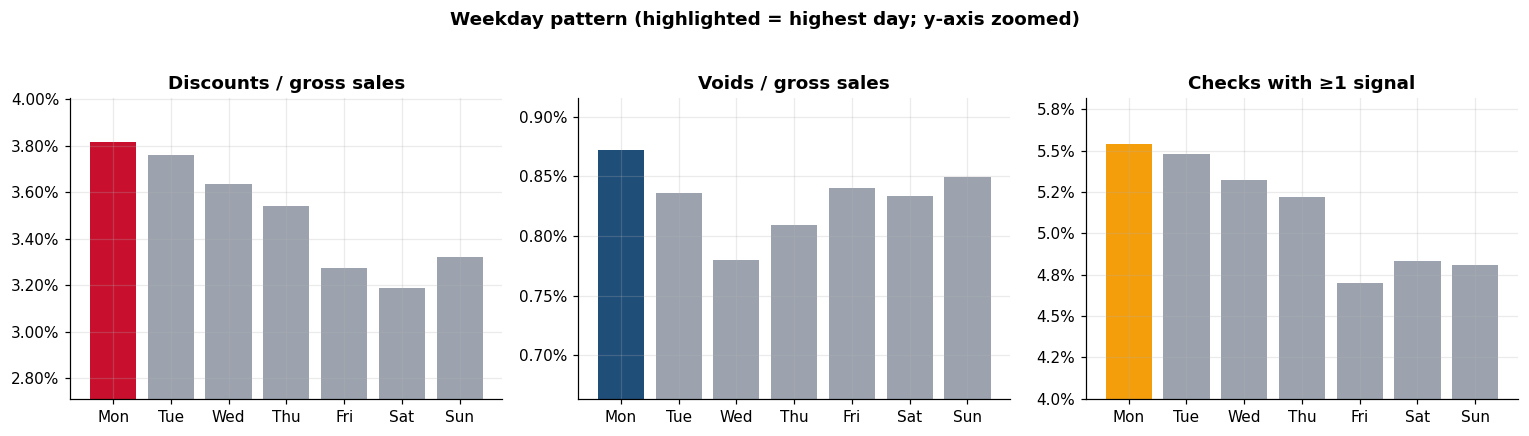

Locations: 127 total | 127 with ≥5,000 checks (used in rankings)


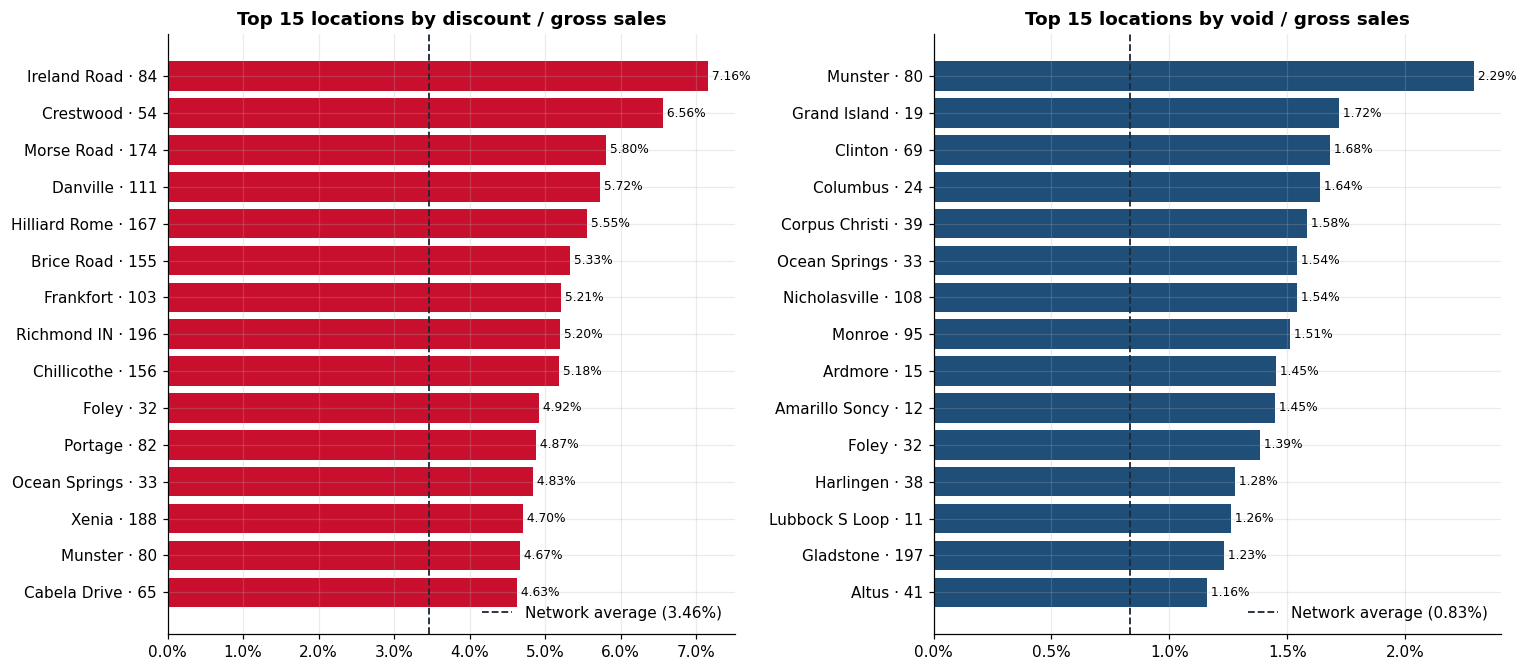

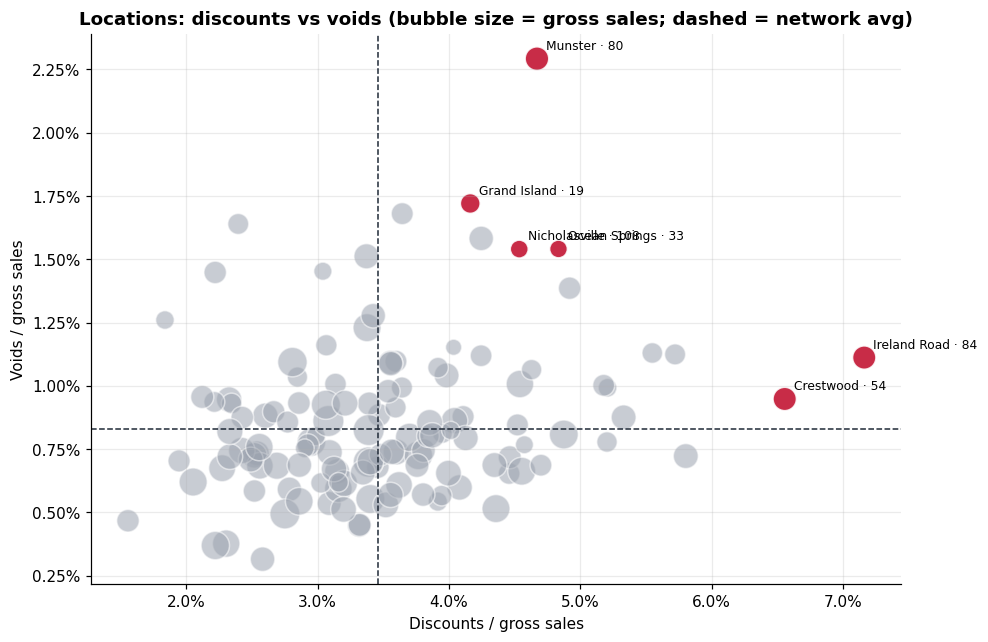

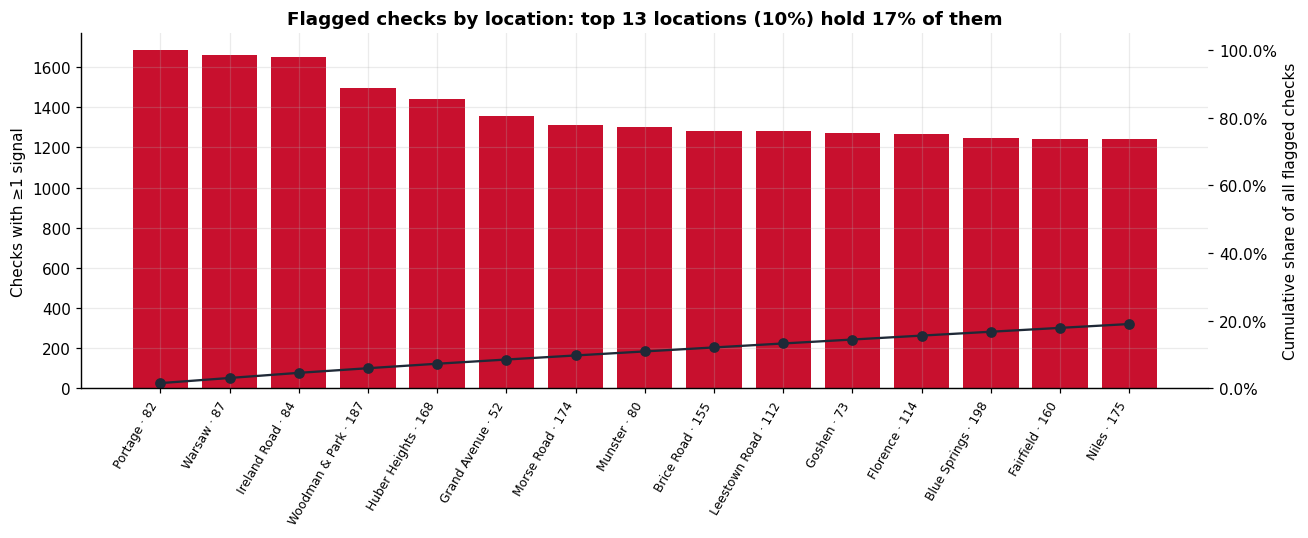

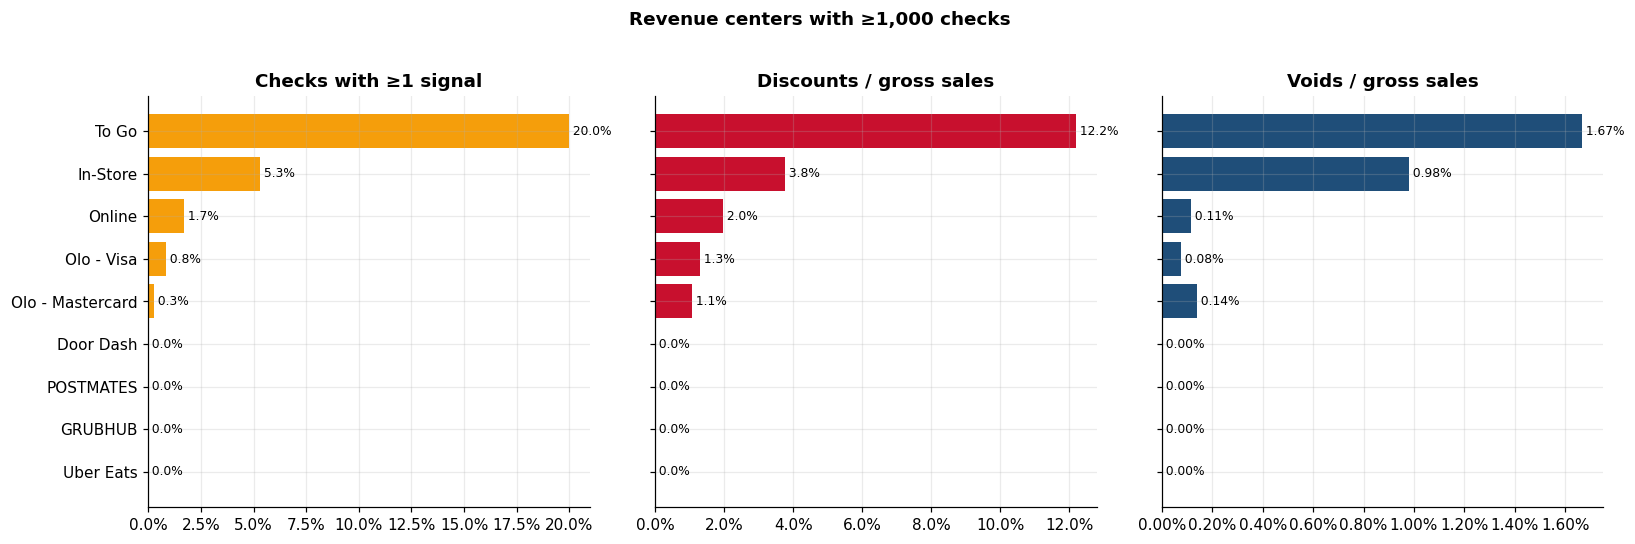

/home/spark-de7a604a-2b75-4b73-a597-34/.ipykernel/62/command-6351477002947038-380037623:294: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  lz["is_outlier"] = lz.is_outlier.fillna(False).astype(bool)


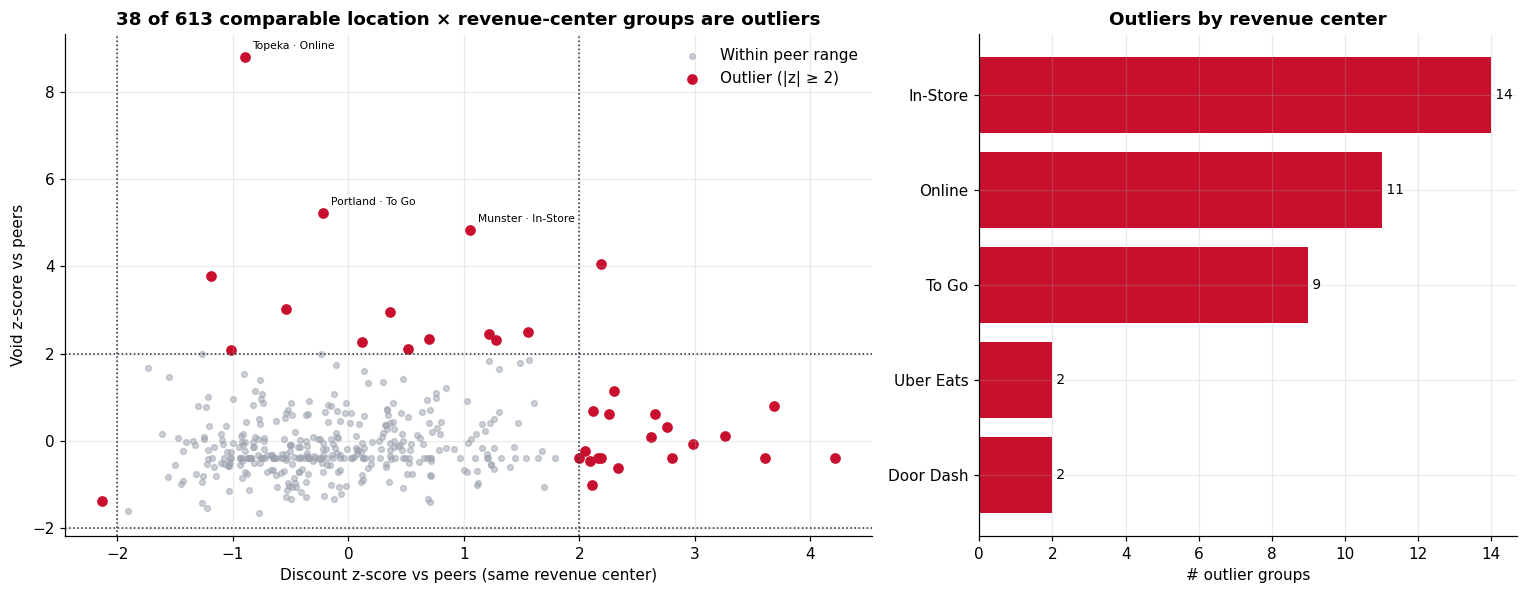

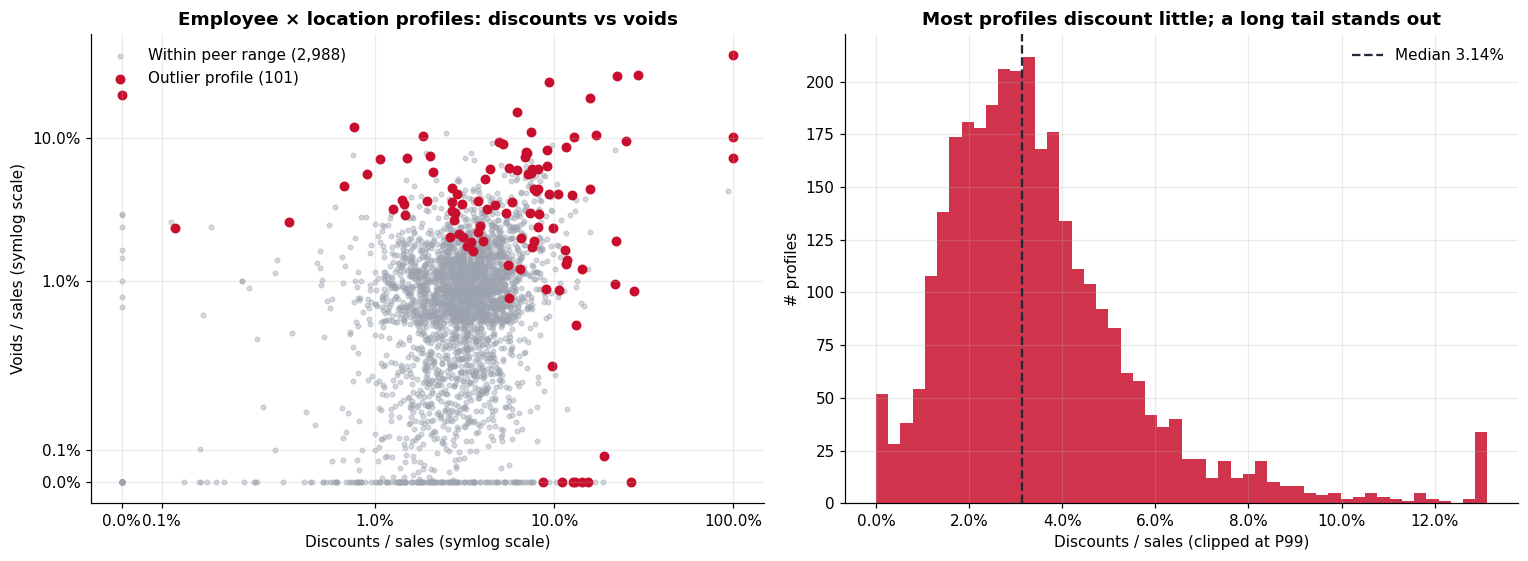

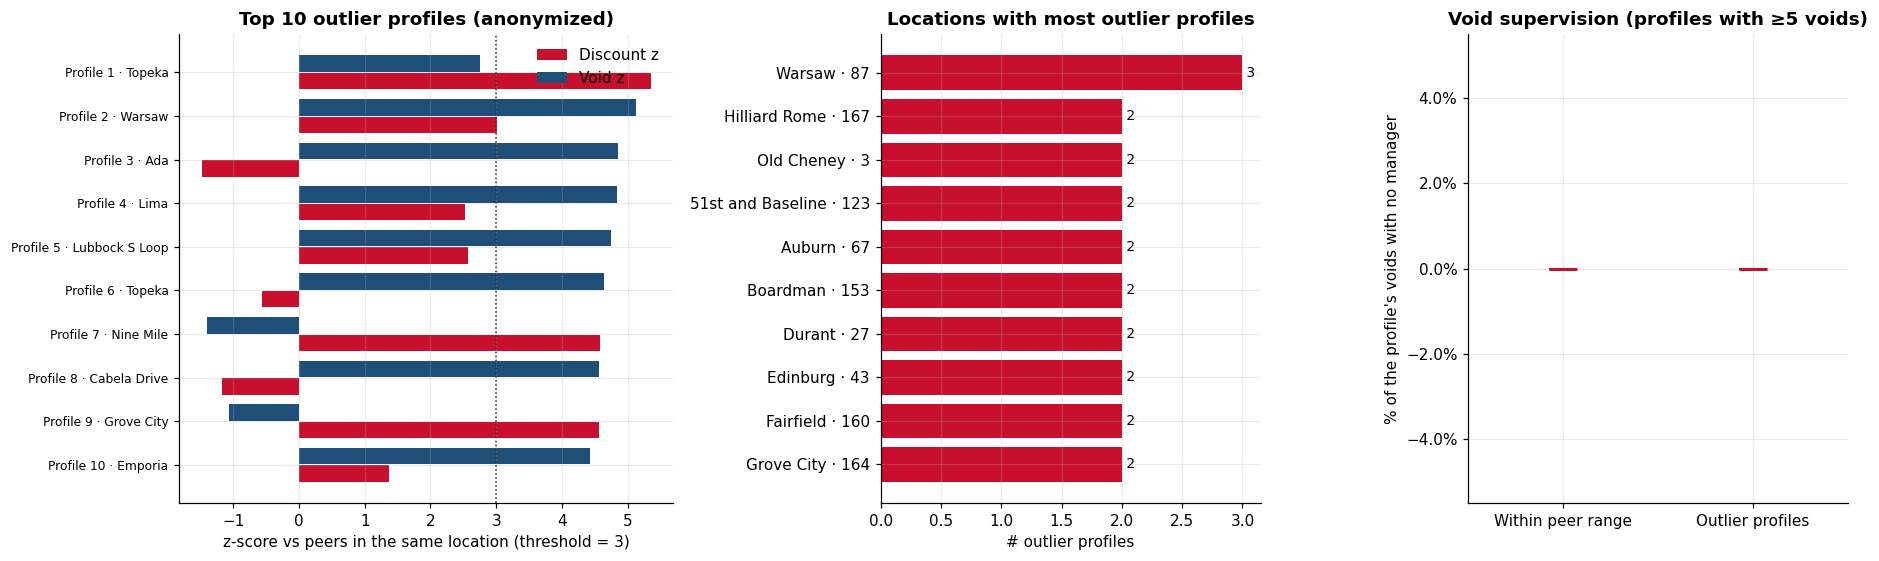

KEY FINDINGS (auto-generated from the Gold tables)
1. Scale: 2,142,846 checks, 2026-04-28 to 2026-08-20; 5.09% carry at least one risk signal.
2. Money: discounts = 3.46% and voids = 0.83% of gross sales.
3. Flagged checks are 5.1% of checks but 57.8% of discount $ and 25.1% of void $.
4. Most frequent signal: 'High discount (≥50% of gross)' (4.43% of checks).
5. Weekday: highest discount day = Mon, highest void day = Mon, highest flagged-check day = Mon.
6. Peak day for flagged checks: 2026-07-13 (7.50%).
7. Concentration: top 13 of 127 locations (10%) hold 17% of flagged checks.
8. Revenue center with the highest flagged rate: To Go (19.98%).
9. Location × revenue-center outliers: 38 of 613 comparable groups.
10. Employee profiles flagged: 101 of 3089 eligible (≥100 item lines).
11. Location with most outlier profiles: Warsaw · 87 (3 profiles).
12. Median share of voids WITHOUT manager: normal profiles 0.0% vs outlier profiles 0.0%.
13. Highest discount+void combined locations: Munst

In [0]:
# Databricks notebook source
# MAGIC %md
# MAGIC ## 11. Visual Analysis of the Gold Tables
# MAGIC Each chart answers one business question and is built only from the validated Gold tables
# MAGIC (`p2_team_gold_*`). Risk signals are indicators for review, not proof of fraud.

# COMMAND ----------

# CELDA 0 · SETUP (ejecutar primero; deja todo listo para las demás celdas)
from pyspark.sql import functions as F
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

SCHEMA = "workspace.default"
tx        = spark.table(f"{SCHEMA}.p2_team_gold_transaction_risk_flags")
daily     = spark.table(f"{SCHEMA}.p2_team_gold_daily_risk_metrics")
locations = spark.table(f"{SCHEMA}.p2_team_gold_location_risk_comparison")
employees = spark.table(f"{SCHEMA}.p2_team_gold_employee_risk_profile")

# Paleta y estilo uniformes para todas las gráficas
RED, DARK, GREY, AMBER, BLUE = "#C8102E", "#1F2937", "#9CA3AF", "#F59E0B", "#1F4E79"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold", "axes.titlesize": 12,
})
PCT1 = mtick.PercentFormatter(xmax=1, decimals=1)   # para razones 0-1
PCT2 = mtick.PercentFormatter(xmax=1, decimals=2)

MIN_LOC_CHECKS = 5000          # ubicaciones con muy poco volumen no se comparan en rankings
INSIGHTS = {}                  # aquí se van guardando los números para la conclusión (celda final)

# Guardar PNG de cada gráfica (para el repo de GitHub). Si no hay permiso, no pasa nada.
FIG_DIR = "/Volumes/workspace/default/applebees_datachefs_raw/figures_phase2"
def save_fig(fig, name):
    try:
        import os
        os.makedirs(FIG_DIR, exist_ok=True)
        fig.savefig(f"{FIG_DIR}/{name}.png", bbox_inches="tight", dpi=200)
    except Exception as e:
        print(f"(PNG not saved: {str(e).splitlines()[0]})  -> use the download option on the chart")

def loc_label(df):
    name = df["location_name"].fillna("Location")
    return name.astype(str) + " · " + df["LocationId"].astype(str)

print("Setup OK")

# COMMAND ----------

# CELDA 1 · KPI TILES  —  Pregunta: ¿qué tan grande es el problema?
kpi = tx.agg(
    F.count("*").alias("checks"),
    F.sum((F.col("risk_score") > 0).cast("int")).alias("flagged"),
    F.sum(F.coalesce("total_gross_price", F.lit(0.0))).alias("gross"),
    F.sum(F.coalesce("discount_total_amount", F.lit(0.0))).alias("disc"),
    F.sum(F.coalesce("void_amount", F.lit(0.0))).alias("void"),
    F.sum(F.when(F.col("risk_score") > 0, F.coalesce("total_gross_price", F.lit(0.0))).otherwise(0.0)).alias("gross_flagged"),
    F.sum(F.when(F.col("risk_score") > 0, F.coalesce("discount_total_amount", F.lit(0.0))).otherwise(0.0)).alias("disc_flagged"),
    F.sum(F.when(F.col("risk_score") > 0, F.coalesce("void_amount", F.lit(0.0))).otherwise(0.0)).alias("void_flagged"),
).first().asDict()
INSIGHTS["kpi"] = kpi

tiles = [
    ("Checks evaluated",            f"{kpi['checks']:,}"),
    ("Checks with ≥1 risk signal",  f"{kpi['flagged']:,}  ({kpi['flagged']/kpi['checks']:.1%})"),
    ("Discounts / gross sales",     f"{kpi['disc']/kpi['gross']:.2%}"),
    ("Voids / gross sales",         f"{kpi['void']/kpi['gross']:.2%}"),
]
fig, axes = plt.subplots(1, 4, figsize=(14, 2.1))
for ax, (title, value) in zip(axes, tiles):
    ax.axis("off")
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, color="#F3F4F6"))
    ax.text(.5, .60, value, ha="center", va="center", fontsize=17, weight="bold", color=RED, transform=ax.transAxes)
    ax.text(.5, .20, title, ha="center", va="center", fontsize=10, color=DARK, transform=ax.transAxes)
fig.suptitle("Executive KPIs — Applebee's transactions (Apr 28 – Aug 20, 2026)", fontweight="bold", y=1.05)
save_fig(fig, "01_kpi_tiles"); plt.show()

# ¿Los checks con señal pesan más en descuentos/voids de lo que pesan en ventas?
share = pd.DataFrame({
    "metric": ["Checks", "Gross sales", "Discount $", "Void $"],
    "share":  [kpi["flagged"] / kpi["checks"],
               kpi["gross_flagged"] / kpi["gross"] if kpi["gross"] else 0,
               kpi["disc_flagged"] / kpi["disc"] if kpi["disc"] else 0,
               kpi["void_flagged"] / kpi["void"] if kpi["void"] else 0],
})
INSIGHTS["share"] = dict(zip(share.metric, share.share))

fig, ax = plt.subplots(figsize=(7.5, 4))
bars = ax.bar(share.metric, share.share, color=[GREY, GREY, RED, RED])
for b, v in zip(bars, share.share):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.1%}", ha="center", va="bottom", fontweight="bold")
ax.yaxis.set_major_formatter(PCT1)
ax.set_ylabel("Share of the total held by flagged checks")
ax.set_title("Flagged checks: small in count, heavy in discounts and voids")
save_fig(fig, "02_flagged_share"); plt.show()

# COMMAND ----------

# CELDA 2 · DISTRIBUCIÓN DE RISK SCORE Y SEÑALES  —  Pregunta: ¿qué tipo de señales aparecen y cuántas a la vez?
LABELS = {
    "risk_fully_voided":         "Fully voided (no items, has voids)",
    "risk_high_discount":        "High discount (≥50% of gross)",
    "risk_no_payment":           "Items but no payment",
    "risk_discount_both_levels": "Discount at check AND item level",
}
score = tx.groupBy("risk_score").count().orderBy("risk_score").toPandas()
sig = (tx.agg(*[F.avg(F.col(f).cast("int")).alias(f) for f in LABELS]).toPandas().T
         .reset_index().rename(columns={"index": "signal", 0: "pct"}))
sig["label"] = sig.signal.map(LABELS)
sig = sig.sort_values("pct")
INSIGHTS["signals"] = dict(zip(sig.label, sig.pct))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
ax = axes[0]
bars = ax.bar(score.risk_score.astype(str), score["count"], color=[GREY] + [RED] * (len(score) - 1))
ax.set_yscale("log")
for b, v in zip(bars, score["count"]):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
ax.set_xlabel("Risk score (number of signals on the check)"); ax.set_ylabel("Checks (log scale)")
ax.set_title("Most checks have no signal; few accumulate several")

ax = axes[1]
ax.barh(sig.label, sig.pct, color=RED)
for y, v in enumerate(sig.pct):
    ax.text(v, y, f" {v:.2%}", va="center", fontsize=9)
ax.xaxis.set_major_formatter(PCT1)
ax.set_xlabel("% of all checks"); ax.set_title("Which signal is the most frequent?")
plt.tight_layout(); save_fig(fig, "03_risk_score_and_signals"); plt.show()

# COMMAND ----------

# CELDA 3 · TENDENCIA DIARIA  —  Pregunta: ¿cambian descuentos, voids y señales a lo largo del tiempo?
d = (daily.groupBy("business_date").agg(
        F.sum("checks").alias("checks"),
        F.sum("gross_sales").alias("gross"),
        F.sum(F.coalesce("item_discount_amount", F.lit(0.0)) + F.coalesce("check_discount_amount", F.lit(0.0))).alias("disc"),
        F.sum("void_amount").alias("void")).toPandas())
fr = tx.groupBy("business_date").agg(F.avg((F.col("risk_score") > 0).cast("int")).alias("flag_rate")).toPandas()
d = d.merge(fr, on="business_date")
d["business_date"] = pd.to_datetime(d["business_date"])
d = d.sort_values("business_date").reset_index(drop=True)
d["disc_pct"], d["void_pct"] = d.disc / d.gross, d.void / d.gross
for c in ["disc_pct", "void_pct", "flag_rate"]:
    d[c + "_7d"] = d[c].rolling(7, center=True, min_periods=3).mean()   # media móvil 7 días

peak = d.loc[d.flag_rate.idxmax()]
INSIGHTS["peak_flag_day"] = (peak.business_date.date(), peak.flag_rate)
INSIGHTS["trend_range"] = (d.business_date.min().date(), d.business_date.max().date())

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax = axes[0]
ax.plot(d.business_date, d.disc_pct, color=RED, alpha=.2); ax.plot(d.business_date, d.disc_pct_7d, color=RED, lw=2, label="Discounts / gross (7-day avg)")
ax.plot(d.business_date, d.void_pct, color=BLUE, alpha=.2); ax.plot(d.business_date, d.void_pct_7d, color=BLUE, lw=2, label="Voids / gross (7-day avg)")
ax.yaxis.set_major_formatter(PCT1); ax.set_ylabel("% of gross sales"); ax.legend(frameon=False)
ax.set_title("Daily discount and void ratios (network-wide)")
ax = axes[1]
ax.plot(d.business_date, d.flag_rate, color=AMBER, alpha=.3); ax.plot(d.business_date, d.flag_rate_7d, color=AMBER, lw=2)
ax.annotate(f"Peak {peak.flag_rate:.1%}\n{peak.business_date:%b %d}", (peak.business_date, peak.flag_rate),
            textcoords="offset points", xytext=(10, 8), fontsize=9, arrowprops=dict(arrowstyle="-", color=DARK))
ax.yaxis.set_major_formatter(PCT1); ax.set_ylabel("% of checks with ≥1 signal")
ax.set_title("Share of checks with risk signals per day")
plt.tight_layout(); save_fig(fig, "04_daily_trend"); plt.show()

# COMMAND ----------

# CELDA 4 · DÍA DE LA SEMANA  —  Pregunta: ¿hay días de la semana con más descuentos, voids o señales?
d["dow"] = d.business_date.dt.dayofweek          # 0 = Monday
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
wk = (d.groupby("dow").apply(lambda g: pd.Series({
        "disc_pct": g.disc.sum() / g.gross.sum(),
        "void_pct": g.void.sum() / g.gross.sum(),
        "flag_rate": (g.flag_rate * g.checks).sum() / g.checks.sum(),
        "checks": g.checks.sum()}), include_groups=False).reset_index())
wk["day"] = wk.dow.map(dict(enumerate(names)))
INSIGHTS["wk"] = wk

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col, color, title in zip(
        axes, ["disc_pct", "void_pct", "flag_rate"], [RED, BLUE, AMBER],
        ["Discounts / gross sales", "Voids / gross sales", "Checks with ≥1 signal"]):
    hi = wk[col].idxmax()
    ax.bar(wk.day, wk[col], color=[color if i == hi else GREY for i in range(len(wk))])
    ax.yaxis.set_major_formatter(PCT2 if col != "flag_rate" else PCT1)
    lo, hi_v = wk[col].min(), wk[col].max()
    ax.set_ylim(lo * 0.85, hi_v * 1.05)      # eje recortado para que la diferencia se vea; aclarar en la presentación
    ax.set_title(title)
fig.suptitle("Weekday pattern (highlighted = highest day; y-axis zoomed)", fontweight="bold", y=1.03)
plt.tight_layout(); save_fig(fig, "05_weekday_pattern"); plt.show()

# COMMAND ----------

# CELDA 5 · RANKING DE LOCATIONS  —  Pregunta: ¿qué locations tienen más descuentos y voids sobre sus ventas?
loc = (daily.groupBy("LocationId", "location_name").agg(
        F.sum("checks").alias("checks"),
        F.sum("gross_sales").alias("gross"),
        F.sum(F.coalesce("item_discount_amount", F.lit(0.0)) + F.coalesce("check_discount_amount", F.lit(0.0))).alias("disc"),
        F.sum("void_amount").alias("void")).toPandas())
locf = tx.groupBy("LocationId").agg(F.sum((F.col("risk_score") > 0).cast("int")).alias("flagged_checks")).toPandas()
loc = loc.merge(locf, on="LocationId", how="left")
loc["disc_pct"], loc["void_pct"] = loc.disc / loc.gross, loc.void / loc.gross
loc["flag_rate"] = loc.flagged_checks / loc.checks
loc["label"] = loc_label(loc)
loc_e = loc[loc.checks >= MIN_LOC_CHECKS].copy()

net_disc, net_void = loc.disc.sum() / loc.gross.sum(), loc.void.sum() / loc.gross.sum()
INSIGHTS.update(n_locations=len(loc), n_locations_eval=len(loc_e), net_disc=net_disc, net_void=net_void)
print(f"Locations: {len(loc)} total | {len(loc_e)} with ≥{MIN_LOC_CHECKS:,} checks (used in rankings)")

fig, axes = plt.subplots(1, 2, figsize=(14, 6.2))
for ax, col, net, color, title in [
        (axes[0], "disc_pct", net_disc, RED,  "Top 15 locations by discount / gross sales"),
        (axes[1], "void_pct", net_void, BLUE, "Top 15 locations by void / gross sales")]:
    top = loc_e.sort_values(col, ascending=False).head(15).iloc[::-1]
    ax.barh(top.label, top[col], color=color)
    ax.axvline(net, color=DARK, ls="--", lw=1.2, label=f"Network average ({net:.2%})")
    for y, v in enumerate(top[col]):
        ax.text(v, y, f" {v:.2%}", va="center", fontsize=8)
    ax.xaxis.set_major_formatter(PCT1); ax.set_title(title); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); save_fig(fig, "06_location_rankings"); plt.show()

# COMMAND ----------

# CELDA 6 · DESCUENTO vs VOID POR LOCATION  —  Pregunta: ¿hay locations altas en AMBAS métricas a la vez?
z = lambda s: (s - s.mean()) / s.std()
loc_e["combo_z"] = z(loc_e.disc_pct) + z(loc_e.void_pct)
top_lab = loc_e.sort_values("combo_z", ascending=False).head(6)

fig, ax = plt.subplots(figsize=(9.5, 6.5))
ax.scatter(loc_e.disc_pct, loc_e.void_pct, s=loc_e.gross / loc_e.gross.max() * 400 + 15, color=GREY, alpha=.55, edgecolor="white")
ax.scatter(top_lab.disc_pct, top_lab.void_pct, s=top_lab.gross / loc_e.gross.max() * 400 + 15, color=RED, alpha=.85, edgecolor="white")
for _, r in top_lab.iterrows():
    ax.annotate(r.label, (r.disc_pct, r.void_pct), textcoords="offset points", xytext=(6, 6), fontsize=8)
ax.axvline(net_disc, color=DARK, ls="--", lw=1); ax.axhline(net_void, color=DARK, ls="--", lw=1)
ax.xaxis.set_major_formatter(PCT1); ax.yaxis.set_major_formatter(PCT2)
ax.set_xlabel("Discounts / gross sales"); ax.set_ylabel("Voids / gross sales")
ax.set_title("Locations: discounts vs voids (bubble size = gross sales; dashed = network avg)")
save_fig(fig, "07_location_scatter"); plt.show()
INSIGHTS["top_combo_locations"] = list(top_lab.label)

# COMMAND ----------

# CELDA 7 · CONCENTRACIÓN (PARETO) DE CHECKS CON SEÑAL  —  Pregunta: ¿el riesgo está disperso o concentrado en pocas locations?
lf = loc.sort_values("flagged_checks", ascending=False).reset_index(drop=True)
lf["cum_share"] = lf.flagged_checks.cumsum() / lf.flagged_checks.sum()
n_loc = len(lf); k10 = int(np.ceil(n_loc * .10))
INSIGHTS.update(pareto_top10pct=lf.cum_share.iloc[k10 - 1], pareto_k10=k10, pareto_top10=lf.cum_share.iloc[9])

top = lf.head(15)
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(range(len(top)), top.flagged_checks, color=RED)
ax.set_xticks(range(len(top))); ax.set_xticklabels(top.label, rotation=60, ha="right", fontsize=8)
ax.set_ylabel("Checks with ≥1 signal")
ax2 = ax.twinx(); ax2.plot(range(len(top)), top.cum_share, color=DARK, marker="o")
ax2.set_ylim(0, 1.05); ax2.yaxis.set_major_formatter(PCT1); ax2.grid(False)
ax2.set_ylabel("Cumulative share of all flagged checks")
ax.set_title(f"Flagged checks by location: top {k10} locations ({k10/n_loc:.0%}) hold {lf.cum_share.iloc[k10-1]:.0%} of them")
plt.tight_layout(); save_fig(fig, "08_pareto_locations"); plt.show()

# COMMAND ----------

# CELDA 8 · POR REVENUE CENTER  —  Pregunta: ¿qué área de venta (bar, comedor, to-go...) concentra más señales?
rc = (tx.groupBy("revenue_center_name").agg(
        F.count("*").alias("checks"),
        F.avg((F.col("risk_score") > 0).cast("int")).alias("flag_rate"),
        F.sum(F.coalesce("discount_total_amount", F.lit(0.0))).alias("disc"),
        F.sum(F.coalesce("void_amount", F.lit(0.0))).alias("void"),
        F.sum(F.coalesce("total_gross_price", F.lit(0.0))).alias("gross")).toPandas())
rc["revenue_center_name"] = rc.revenue_center_name.fillna("Unknown")
rc = rc[rc.checks >= 1000].copy()
rc["disc_pct"], rc["void_pct"] = rc.disc / rc.gross, rc.void / rc.gross
rc = rc.sort_values("flag_rate")
INSIGHTS["rc_top"] = (rc.iloc[-1].revenue_center_name, rc.iloc[-1].flag_rate)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
for ax, col, color, title, fmt in [
        (axes[0], "flag_rate", AMBER, "Checks with ≥1 signal", PCT1),
        (axes[1], "disc_pct",  RED,   "Discounts / gross sales", PCT1),
        (axes[2], "void_pct",  BLUE,  "Voids / gross sales", PCT2)]:
    ax.barh(rc.revenue_center_name, rc[col], color=color)
    for y, v in enumerate(rc[col]):
        ax.text(v, y, f" {v:.1%}" if col != "void_pct" else f" {v:.2%}", va="center", fontsize=8)
    ax.xaxis.set_major_formatter(fmt); ax.set_title(title)
fig.suptitle("Revenue centers with ≥1,000 checks", fontweight="bold", y=1.02)
plt.tight_layout(); save_fig(fig, "09_revenue_centers"); plt.show()

# COMMAND ----------

# CELDA 9 · OUTLIERS LOCATION × REVENUE CENTER  —  Pregunta: ¿qué combinaciones se salen de su grupo comparable?
lz = (locations.filter(F.col("void_z").isNotNull() | F.col("discount_z").isNotNull())
        .select("LocationId", "location_name", "revenue_center_name", "checks", "void_z", "discount_z", "is_outlier")
        .toPandas())
lz["is_outlier"] = lz.is_outlier.fillna(False).astype(bool)
lz["lab"] = lz.location_name.fillna("Location").astype(str) + " · " + lz.revenue_center_name.fillna("RC").astype(str)
lz["maxz"] = lz[["void_z", "discount_z"]].abs().max(axis=1)
INSIGHTS["lrc"] = (int(lz.is_outlier.sum()), len(lz))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
ax.scatter(lz[~lz.is_outlier].discount_z, lz[~lz.is_outlier].void_z, s=14, color=GREY, alpha=.5, label="Within peer range")
ax.scatter(lz[lz.is_outlier].discount_z, lz[lz.is_outlier].void_z, s=36, color=RED, label="Outlier (|z| ≥ 2)")
for _, r in lz.sort_values("maxz", ascending=False).head(5).iterrows():
    ax.annotate(r.lab, (r.discount_z, r.void_z), textcoords="offset points", xytext=(5, 5), fontsize=7)
for v in (-2, 2):
    ax.axvline(v, color=DARK, ls=":", lw=1); ax.axhline(v, color=DARK, ls=":", lw=1)
ax.set_xlabel("Discount z-score vs peers (same revenue center)"); ax.set_ylabel("Void z-score vs peers")
ax.set_title(f"{int(lz.is_outlier.sum())} of {len(lz)} comparable location × revenue-center groups are outliers")
ax.legend(frameon=False)

ax = axes[1]
by_rc = lz[lz.is_outlier].groupby(lz.revenue_center_name.fillna("RC")).size().sort_values()
ax.barh(by_rc.index, by_rc.values, color=RED)
for y, v in enumerate(by_rc.values):
    ax.text(v, y, f" {v}", va="center", fontsize=9)
ax.set_xlabel("# outlier groups"); ax.set_title("Outliers by revenue center")
plt.tight_layout(); save_fig(fig, "10_location_rc_outliers"); plt.show()

# COMMAND ----------

# CELDA 10 · EMPLEADOS: DESCUENTO vs VOID  —  Pregunta: ¿cómo se distribuyen los perfiles de empleado y quiénes se separan?
# Nota: se excluye EmployeeId = 0 (placeholder del POS) y perfiles con < 100 líneas vendidas (igual que el pipeline).
emp = (employees.filter((F.col("EmployeeId") != 0) & (F.col("items_sold_lines") >= 100))
        .select("EmployeeId", "LocationId", "location_name", "checks_touched", "items_sold_lines", "gross_sales",
                "void_count", "void_pct_of_sales", "discount_pct_of_sales", "voids_no_manager_pct",
                "void_z", "discount_z", "is_outlier").toPandas())
emp["is_outlier"] = emp.is_outlier.fillna(False).astype(bool)
INSIGHTS["emp"] = (int(emp.is_outlier.sum()), len(emp))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
ax = axes[0]
n_, o_ = emp[~emp.is_outlier], emp[emp.is_outlier]
ax.scatter(n_.discount_pct_of_sales, n_.void_pct_of_sales, s=9, color=GREY, alpha=.4, label=f"Within peer range ({len(n_):,})")
ax.scatter(o_.discount_pct_of_sales, o_.void_pct_of_sales, s=30, color=RED, label=f"Outlier profile ({len(o_):,})")
ax.set_xscale("symlog", linthresh=.005); ax.set_yscale("symlog", linthresh=.005)
ax.xaxis.set_major_formatter(PCT1); ax.yaxis.set_major_formatter(PCT1)
ax.set_xlabel("Discounts / sales (symlog scale)"); ax.set_ylabel("Voids / sales (symlog scale)")
ax.set_title("Employee × location profiles: discounts vs voids"); ax.legend(frameon=False)

ax = axes[1]
cap = emp.discount_pct_of_sales.quantile(.99)
ax.hist(emp.discount_pct_of_sales.clip(upper=cap), bins=50, color=RED, alpha=.85)
ax.axvline(emp.discount_pct_of_sales.median(), color=DARK, ls="--", label=f"Median {emp.discount_pct_of_sales.median():.2%}")
ax.xaxis.set_major_formatter(PCT1); ax.set_xlabel("Discounts / sales (clipped at P99)"); ax.set_ylabel("# profiles")
ax.set_title("Most profiles discount little; a long tail stands out"); ax.legend(frameon=False)
plt.tight_layout(); save_fig(fig, "11_employee_scatter"); plt.show()

# COMMAND ----------

# CELDA 11 · EMPLEADOS ATÍPICOS: DÓNDE ESTÁN Y SI HUBO SUPERVISIÓN  —  Preguntas: ¿cuáles son los más atípicos? ¿se concentran? ¿los voids tienen gerente?
# Los perfiles se anonimizan (Profile 1, 2...) a propósito: la presentación no debe exponer nombres de empleados.
o = emp[emp.is_outlier].copy()
o["maxz"] = o[["void_z", "discount_z"]].max(axis=1)
topo = o.sort_values("maxz", ascending=False).head(10).iloc[::-1].reset_index(drop=True)
topo["lab"] = ["Profile " + str(len(topo) - i) + " · " + str(n) for i, n in enumerate(topo.location_name.fillna("Location"))]

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw={"width_ratios": [1.3, 1, 1]})
ax = axes[0]
yy = np.arange(len(topo))
ax.barh(yy - .2, topo.discount_z.fillna(0), height=.38, color=RED, label="Discount z")
ax.barh(yy + .2, topo.void_z.fillna(0), height=.38, color=BLUE, label="Void z")
ax.set_yticks(yy); ax.set_yticklabels(topo.lab, fontsize=8)
ax.axvline(3, color=DARK, ls=":", lw=1)
ax.set_xlabel("z-score vs peers in the same location (threshold = 3)"); ax.set_title("Top 10 outlier profiles (anonymized)")
ax.legend(frameon=False)

ax = axes[1]
byloc = o.groupby(o.location_name.fillna("Location").astype(str) + " · " + o.LocationId.astype(str)).size().sort_values().tail(10)
ax.barh(byloc.index, byloc.values, color=RED)
for y, v in enumerate(byloc.values):
    ax.text(v, y, f" {v}", va="center", fontsize=9)
ax.set_xlabel("# outlier profiles"); ax.set_title("Locations with most outlier profiles")
INSIGHTS["emp_loc_max"] = (byloc.index[-1], int(byloc.values[-1])) if len(byloc) else None

ax = axes[2]
sup = emp[emp.void_count >= 5]
data = [sup[~sup.is_outlier].voids_no_manager_pct.dropna(), sup[sup.is_outlier].voids_no_manager_pct.dropna()]
ax.boxplot(data, tick_labels=["Within peer range", "Outlier profiles"], showfliers=False,
           patch_artist=True, boxprops=dict(facecolor="#F3F4F6"), medianprops=dict(color=RED, lw=2))
ax.yaxis.set_major_formatter(PCT1); ax.set_ylabel("% of the profile's voids with no manager")
ax.set_title("Void supervision (profiles with ≥5 voids)")
INSIGHTS["no_mgr"] = (data[0].median() if len(data[0]) else np.nan, data[1].median() if len(data[1]) else np.nan)
plt.tight_layout(); save_fig(fig, "12_employee_outliers"); plt.show()

# COMMAND ----------

# CELDA 12 · RESUMEN AUTOMÁTICO PARA LA CONCLUSIÓN EJECUTIVA
# Imprime los números reales calculados arriba. Úsalos para redactar tu conclusión y las diapositivas.
I = INSIGHTS
k = I["kpi"]
print("=" * 70)
print("KEY FINDINGS (auto-generated from the Gold tables)")
print("=" * 70)
print(f"1. Scale: {k['checks']:,} checks, {I['trend_range'][0]} to {I['trend_range'][1]}; "
      f"{k['flagged']/k['checks']:.2%} carry at least one risk signal.")
print(f"2. Money: discounts = {k['disc']/k['gross']:.2%} and voids = {k['void']/k['gross']:.2%} of gross sales.")
s = I["share"]
print(f"3. Flagged checks are {s['Checks']:.1%} of checks but {s['Discount $']:.1%} of discount $ and {s['Void $']:.1%} of void $.")
top_sig = max(I["signals"], key=I["signals"].get)
print(f"4. Most frequent signal: '{top_sig}' ({I['signals'][top_sig]:.2%} of checks).")
wk = I["wk"]
print(f"5. Weekday: highest discount day = {wk.loc[wk.disc_pct.idxmax(), 'day']}, "
      f"highest void day = {wk.loc[wk.void_pct.idxmax(), 'day']}, "
      f"highest flagged-check day = {wk.loc[wk.flag_rate.idxmax(), 'day']}.")
print(f"6. Peak day for flagged checks: {I['peak_flag_day'][0]} ({I['peak_flag_day'][1]:.2%}).")
print(f"7. Concentration: top {I['pareto_k10']} of {I['n_locations']} locations (10%) hold {I['pareto_top10pct']:.0%} of flagged checks.")
print(f"8. Revenue center with the highest flagged rate: {I['rc_top'][0]} ({I['rc_top'][1]:.2%}).")
print(f"9. Location × revenue-center outliers: {I['lrc'][0]} of {I['lrc'][1]} comparable groups.")
print(f"10. Employee profiles flagged: {I['emp'][0]} of {I['emp'][1]} eligible (≥100 item lines).")
if I.get("emp_loc_max"):
    print(f"11. Location with most outlier profiles: {I['emp_loc_max'][0]} ({I['emp_loc_max'][1]} profiles).")
print(f"12. Median share of voids WITHOUT manager: normal profiles {I['no_mgr'][0]:.1%} vs outlier profiles {I['no_mgr'][1]:.1%}.")
print(f"13. Highest discount+void combined locations: {', '.join(I['top_combo_locations'][:3])}.")
print("-" * 70)
print("Reminder: risk signals prioritize review; they are not proof of fraud or misconduct.")

## 10. Executive Summary

This section consolidates the main quantitative indicators into a concise summary for the final presentation.

The summary reports observed values from the Gold tables. Business conclusions should only be written after reviewing the outputs, data-quality results, and relevant limitations.

In [0]:
# Reutilizar los KPI calculados en el Paso 4.
print("=" * 60)
print("SUNHOLDINGS — BUSINESS ANALYSIS SUMMARY")
print("=" * 60)

print(f"Checks evaluated: {checks_evaluated:,}")
print(f"Checks with risk signals: {checks_with_signals:,}")

if risk_signal_rate is not None:
    print(f"Risk-signal rate: {risk_signal_rate:.2f}%")
else:
    print("Risk-signal rate: not calculable")

if discount_to_sales is not None:
    print(f"Discount-to-gross-sales ratio: {discount_to_sales:.2f}%")
else:
    print("Discount-to-gross-sales ratio: not calculable")

if void_to_sales is not None:
    print(f"Void-to-gross-sales ratio: {void_to_sales:.2f}%")
else:
    print("Void-to-gross-sales ratio: not calculable")

print("-" * 60)

# Rango temporal analizado.
date_range = daily.agg(
    F.min("business_date").alias("first_date"),
    F.max("business_date").alias("last_date")
).first()

print(f"First business date: {date_range['first_date']}")
print(f"Last business date: {date_range['last_date']}")

# Número de ubicaciones y grupos comparables marcados.
location_outliers = locations.filter(
    F.col("is_outlier") == True
).count()

location_comparable = locations.filter(
    F.col("is_outlier").isNotNull()
).count()

employee_outliers = employees.filter(
    F.col("is_outlier") == True
).count()

employee_comparable = employees.filter(
    F.col("is_outlier").isNotNull()
).count()

print("-" * 60)
print(
    f"Location/revenue-center outliers: "
    f"{location_outliers:,} of {location_comparable:,} comparable records"
)

print(
    f"Employee profiles flagged: "
    f"{employee_outliers:,} of {employee_comparable:,} profiles with a comparison result"
)

print("=" * 60)
print("Review these results alongside the data-quality evidence.")
print("Risk flags are indicators for investigation, not proof of fraud.")

SUNHOLDINGS — BUSINESS ANALYSIS SUMMARY
Checks evaluated: 2,142,846
Checks with risk signals: 109,083
Risk-signal rate: 5.09%
Discount-to-gross-sales ratio: 3.46%
Void-to-gross-sales ratio: 0.83%
------------------------------------------------------------
First business date: 2026-04-28
Last business date: 2026-08-20
------------------------------------------------------------
Location/revenue-center outliers: 38 of 389 comparable records
Employee profiles flagged: 101 of 3,089 profiles with a comparison result
Review these results alongside the data-quality evidence.
Risk flags are indicators for investigation, not proof of fraud.
